# JS11 – Klasifikasi 2: Praktikum 2
## Klasifikasi SVM dengan Data Dummy Non-Linier

**Tujuan praktikum**

1. Menunjukkan bahwa SVM linear gagal pada data yang tidak terpisah secara linear.
2. Memahami **kernel trick** sebagai cara memetakan data ke ruang berdimensi lebih tinggi.
3. Menggunakan **kernel RBF** untuk membentuk decision boundary non-linear.
4. Membandingkan performa SVM linear dan SVM RBF.
5. Memahami peran parameter `C` dan `gamma` pada kernel RBF.

**Tentang data:** Data dibuat dengan `make_circles` sebanyak 100 titik, dengan satu kelas di lingkaran dalam dan satu kelas di lingkaran luar. Kedua kelas tidak dapat dipisahkan oleh satu garis lurus.

> SVM linear hanya dapat membuat batas keputusan berupa garis lurus. Kernel RBF memungkinkan SVM membuat batas keputusan melengkung dengan mengukur kemiripan titik terhadap support vector.

### 0. Import library dan fungsi plotting

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

from sklearn.datasets import make_circles
from sklearn.svm import SVC

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 6)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


In [2]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    '''Plot decision boundary, margin, dan support vector untuk SVM 2D.'''
    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    ax.contour(
        X_grid,
        Y,
        P,
        colors="k",
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=["--", "-", "--"],
    )

    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors="none",
            edgecolors="k",
            label="Support vector",
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### 1. Data non-linear dan kegagalan SVM linear

Akurasi SVM linear: 0.68
Jumlah support vector: 100


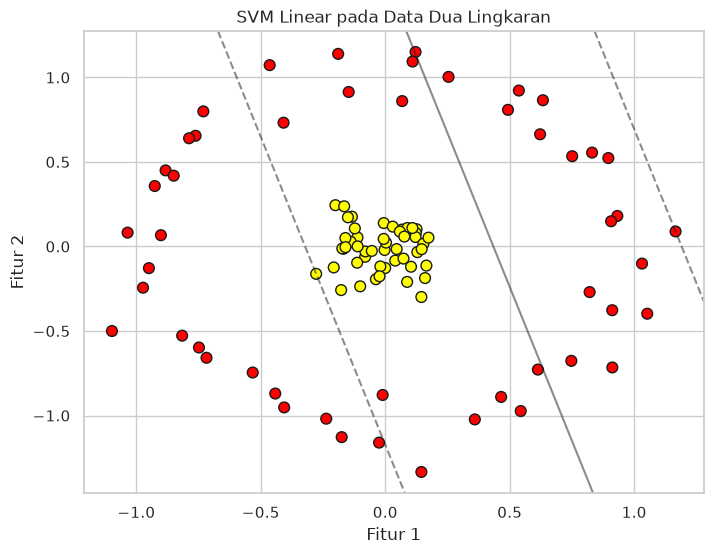

In [3]:
X, y = make_circles(
    n_samples=100,
    factor=0.1,
    noise=0.1,
    random_state=0,
)

clf_linear = SVC(kernel="linear")
clf_linear.fit(X, y)

print("Akurasi SVM linear:", clf_linear.score(X, y))
print("Jumlah support vector:", len(clf_linear.support_vectors_))

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=60, cmap="autumn", edgecolor="k")
plot_svc_decision_function(clf_linear, plot_support=False)
plt.title("SVM Linear pada Data Dua Lingkaran")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

SVM linear hanya mencapai akurasi sekitar **0,68**. Garis lurus tidak dapat memisahkan lingkaran dalam dari lingkaran luar. Diperlukan representasi atau kernel yang mampu menangkap hubungan radial.

### 2. Proyeksi radial ke ruang tiga dimensi

Salah satu cara memahami kernel trick adalah memetakan setiap titik dengan fitur radial:

$$
r = \exp\left(-\sum_{j} x_j^2\right)
$$

Titik di lingkaran dalam memiliki nilai `r` yang tinggi, sedangkan titik di lingkaran luar memiliki nilai `r` yang rendah. Dengan fitur tambahan `r`, data menjadi terpisah oleh sebuah bidang datar di ruang 3D.

Rentang r: 0.16530729135267042 hingga 0.9995645772598666
Rata-rata r kelas 0: 0.3557296916430759
Rata-rata r kelas 1: 0.9700356997270535


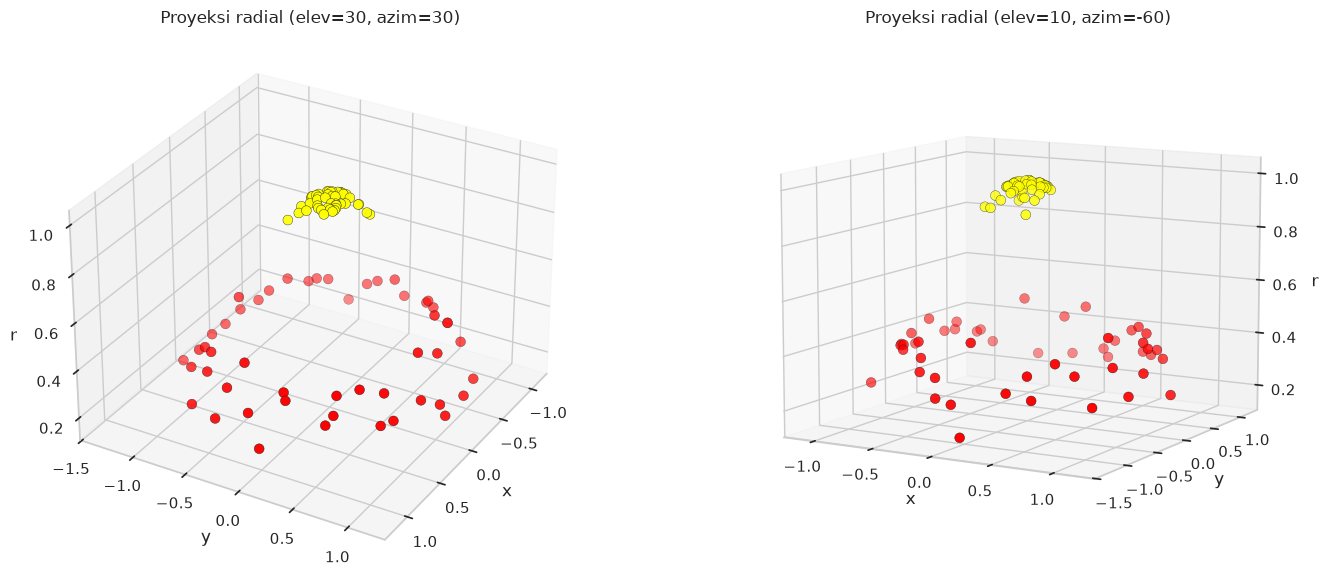

In [4]:
r = np.exp(-(X ** 2).sum(axis=1))

print("Rentang r:", r.min(), "hingga", r.max())
print("Rata-rata r kelas 0:", r[y == 0].mean())
print("Rata-rata r kelas 1:", r[y == 1].mean())

fig = plt.figure(figsize=(15, 6))

for i, (elev, azim) in enumerate([(30, 30), (10, -60)], start=1):
    ax = fig.add_subplot(1, 2, i, projection="3d")
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap="autumn", edgecolor="k", linewidth=0.3)
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("r")
    ax.set_title(f"Proyeksi radial (elev={elev}, azim={azim})")

plt.tight_layout()
plt.show()

Pada ruang 3D, kedua kelas dapat dipisahkan oleh sebuah bidang. SVM tidak perlu benar-benar menghitung koordinat 3D secara eksplisit; kernel RBF menghitung hasil kali dalam yang ekuivalen dengan proyeksi tersebut. Inilah inti **kernel trick**.

### 3. SVM dengan kernel RBF

Akurasi SVM RBF: 1.0
Jumlah support vector: 10


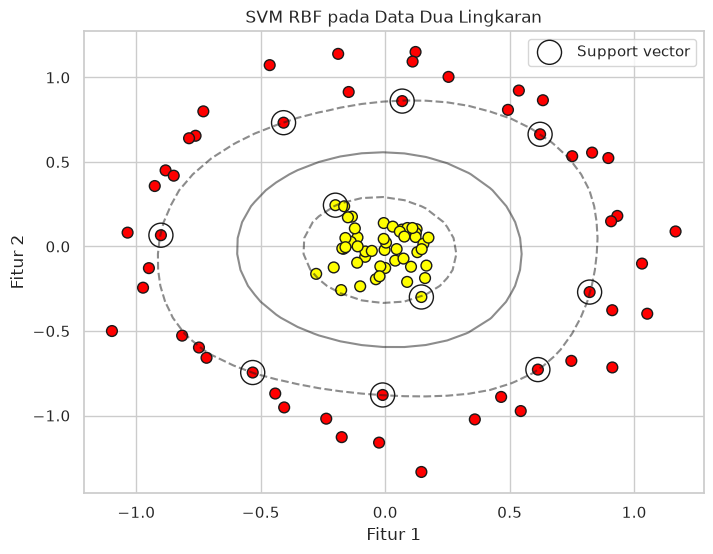

In [5]:
clf_rbf = SVC(kernel="rbf", C=1e6)
clf_rbf.fit(X, y)

print("Akurasi SVM RBF:", clf_rbf.score(X, y))
print("Jumlah support vector:", len(clf_rbf.support_vectors_))

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=60, cmap="autumn", edgecolor="k")
plot_svc_decision_function(clf_rbf)
plt.title("SVM RBF pada Data Dua Lingkaran")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.legend()
plt.show()

### 4. Perbandingan SVM linear dan RBF

In [6]:
perbandingan = pd.DataFrame({
    "Model": ["SVM Linear", "SVM RBF (C=1e6)"],
    "Kernel": ["linear", "rbf"],
    "Akurasi": [clf_linear.score(X, y), clf_rbf.score(X, y)],
    "Jumlah support vector": [
        len(clf_linear.support_vectors_),
        len(clf_rbf.support_vectors_),
    ],
})
perbandingan.round(4)

,Model,Kernel,Akurasi,Jumlah support vector
0,SVM Linear,linear,0.68,100
1,SVM RBF (C=1e6),rbf,1.00,10


### 5. Interpretasi dan kesimpulan

**Hasil**

- SVM linear: akurasi **0,68**, dengan 100 support vector. Semua titik menjadi support vector karena tidak ada garis lurus yang mampu memisahkan kelas.
- SVM RBF: akurasi **1,0**, dengan 10 support vector.

**Mengapa RBF berhasil?**

Kernel RBF mengukur kemiripan sebuah titik dengan support vector berdasarkan jarak:

$$
K(x, x') = \exp(-\gamma \|x - x'\|^2)
$$

Titik yang dekat dengan support vector tertentu mendapat pengaruh besar, sedangkan titik yang jauh mendapat pengaruh kecil. Dengan menggabungkan banyak support vector, SVM dapat membentuk batas keputusan melengkung yang mengikuti struktur lingkaran.

**Peran hyperparameter**

- **C** mengontrol penalti kesalahan. Nilai C besar membuat model berusaha mengklasifikasikan semua data latih dengan benar, tetapi berisiko overfitting.
- **gamma** mengontrol luas pengaruh satu titik. Gamma kecil membuat pengaruh menyebar dan boundary lebih halus; gamma besar membuat pengaruh sempit dan boundary sangat tajam.
- Pada data lingkaran ini, `C=1e6` dan gamma default (`scale`) sudah mampu mencapai akurasi sempurna.

**Keterbatasan**

- Data hanya 100 titik dan dibuat bersih; hasil sempurna belum tentu berlaku pada data nyata.
- Nilai C yang sangat besar dapat menghasilkan boundary yang terlalu mengikuti noise.
- Kernel RBF sulit diinterpretasikan secara langsung karena bekerja di ruang fitur berdimensi tinggi.

**Kesimpulan**

1. SVM linear gagal pada data non-linear karena batasnya hanya berupa garis lurus.
2. Proyeksi radial menunjukkan bahwa data lingkaran dapat dipisahkan di ruang dimensi yang lebih tinggi.
3. Kernel RBF mencapai akurasi **1,0** tanpa menghitung transformasi eksplisit.
4. Pemilihan kernel dan hyperparameter sangat penting untuk data non-linear.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS11 – Klasifikasi 2, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2
- `scikit-learn` – RBF SVM. https://scikit-learn.org/stable/modules/svm.html#kernel-functions
- StatQuest – SVM Poly Kernel. https://www.youtube.com/watch?v=Toet3EiSFcM
- StatQuest – SVM RBF Kernel. https://www.youtube.com/watch?v=Qc5IyLW_hns